# Notebook 1 -- Data Preparation

**Purpose**: Load the shapefile, validate and fix CRS, match drops to DOB rasters, build drop_id, convert dates to day-of-year, and save a clean drops file for use in downstream notebooks. 

**Output**: `drops_clean.geojson` -- the prepared shapefile ready for feature extraction

In [1]:
# Importing necessary modules
import geopandas as gpd
import rasterio
import os
import numpy as np
import pandas as pd 
from rasterio.mask import mask

In [2]:
# importing the drop file from the training data [2017/2018]
drops = gpd.read_file("../training_data/buffered_drops/cleaned_drop_buffers.shp")

In [3]:
# checking if every rows in a shape file has a corresponding tif file or not. 
tif_dir = "../training_data/DOBs"

# creates a dictionary of tif_files as {"file_name": "file_name.tif"}
tif_files = {f.replace(".dob.tif", ""): f for f in os.listdir(tif_dir) if f.endswith(".tif")}


drops["Evnt_ID_str"] = drops["Evnt_ID"].astype("str")
matched_mask = drops["Evnt_ID_str"].isin(tif_files.keys())

print(f"Matched: {matched_mask.sum()} / {len(drops)}")
print(f"Unmatched: {(~matched_mask).sum()}")



# Every fire has a unique Evnt_ID. A particular fire might have more than one drops. Hence, grouping them by event id to get the number of unique fire incidents that had drops on them.  
print(f"Unique Event Ids: {drops.groupby('Evnt_ID_str').size().count()} ")

# lenth of tif files gives us the total count of fires. 
print(f"Total Fire Incidents: {len(tif_files)}")

tif_ids = set(tif_files.keys())
shp_ids = set(drops["Evnt_ID_str"].unique())

missing_from_shp = tif_ids - shp_ids
print(f"Fire(s) with missing drops: {len(missing_from_shp)}")
print(list(missing_from_shp))

Matched: 21234 / 21234
Unmatched: 0
Unique Event Ids: 424 
Total Fire Incidents: 444
Fire(s) with missing drops: 20
['MT4622411032120170910', 'WA4617012050020180901', 'CA3805012095020180629', 'OR4318212230620170809', 'WA4665411975020180719', 'ID4540111652720170908', 'OR4400912217020170804', 'MT4764110818620190809', 'AZ3641211314120190805', 'CA3502012029920170706', 'OR4470812185620170724', 'CA3372011680020180725', 'CA3958812158520171009', 'OR4340212236220170810', 'MT4750210822520190801', 'CA3367611751620180806', 'OR4307312203920180715', 'WA4824811858220170809', 'CA3553111864820170730', 'ID4447411719020180725']


In [4]:
# Building the lookup. Adding a new variable "tif_path" which contains the full path of the tif file corresponding to the given drop.
def get_tif_path(event_id):
    fname = tif_files.get(str(event_id))
    if fname is None:
        return None
    return os.path.join(tif_dir, fname)

drops["tif_path"] = drops["Evnt_ID_str"].apply(get_tif_path)

missing = drops["tif_path"].isna().sum()
print(f"Dropping {missing} rows with no matching raster")
drops = drops.dropna(subset=["tif_path"])

Dropping 0 rows with no matching raster


In [5]:
# Confirming CRS Alignment
# We will be using ESPG:5070 as the raster file is already in the given CRS. Reprojecting the shapefile to the CRS to maintain consistency. 
sample_tif = drops["tif_path"].iloc[0]
with rasterio.open(sample_tif) as src:
    raster_crs = src.crs
    print(f"Raster CRS {src.crs}")
    print(f"Raster nodata: ", src.nodata)

print("Shapefile CRS: ", drops.crs)

if drops.crs != raster_crs:
    drops = drops.set_crs(raster_crs, allow_override=True)
    print("Reprojected drops to match raster CRS")
    


Raster CRS EPSG:5070
Raster nodata:  65535.0
Shapefile CRS:  PROJCS["unknown",GEOGCS["unknown",DATUM["D_Unknown_based_on_GRS_1980_ellipsoid_using_towgs84_1_1_-1_0_0_0_0",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Reprojected drops to match raster CRS


In [6]:
#Verifying CRS
print(drops.crs)
print(drops.crs == raster_crs)


PROJCS["unnamed",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
True


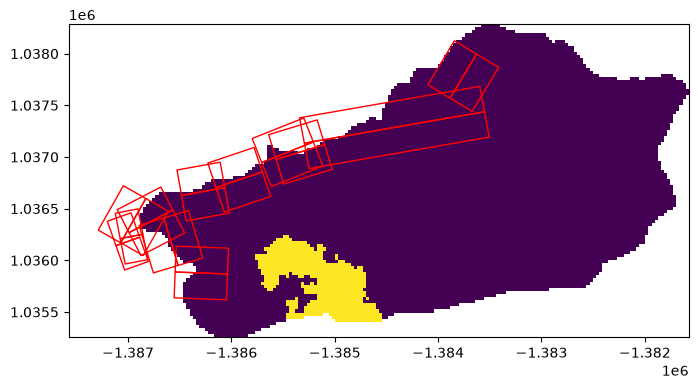

In [7]:
# Visualizing where or not the data is loaded properly. 

import matplotlib.pyplot as plt
import rasterio.plot

row = drops.iloc[0]
fig,ax = plt.subplots(figsize=(8,8))
with rasterio.open(row["tif_path"]) as src:
    rasterio.plot.show(src,ax=ax)

drops[drops["Evnt_ID_str"] == row["Evnt_ID_str"]].plot(ax=ax, facecolor="none", edgecolor="red")
plt.show()

In [8]:
# Creating the local_date field in drops for a timestamp of the drop. 
import pandas as pd

drops["local_date"] = pd.to_datetime(
    dict(
        year=drops["loclYr1"].astype(int),
        month=drops["lclMnth"].astype(int),
        day=drops["loclDy1"].astype(int)
    ),
    errors="coerce"
)

# adding a drop_doy (drop day of year) to correspond with the raster information. 
drops["drop_doy"] = drops["local_date"].dt.dayofyear


In [9]:
# Creating a unique drop_id 

drops["drop_id"] = (
    drops["Evnt_ID"].astype(str) + "_" +
    drops["Latitd1"].round(5).astype(str) + "_" +
    drops["Longtd1"].round(5).astype(str) + "_" +
    drops["UTCdtTm"]
)

In [10]:
# Verify pairing: most drop_ids should group exactly 2 rows
print(drops.groupby("drop_id").size().value_counts())

2    10367
4      111
1       41
6        2
3        1
Name: count, dtype: int64


In [11]:
# ---- Save Clean Drops ----
# Saving the prepared drops to disk so downstream notebooks
# don't need to repeat all the above steps.
drops.to_file("drops_clean.geojson", driver="GeoJSON")
print(f"Saved {len(drops)} rows to drops_clean.geojson")

Saved 21234 rows to drops_clean.geojson
